# Imports


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from src.utils.loading_data import *
from src.utils.data_inspection import *
from src.utils.data_inspection_viz import *
from src.utils.metadata_enrich import *
from src.utils.data_cleaning import *

# Loading Metadata

In [3]:
from src.utils.loading_data import load_nasdaq_metadata

meta = load_nasdaq_metadata("data/symbols_valid_meta.csv")



# Metadata vizualisations, Enrichment And Cleaning


As we planned to make comparison through different market categories for Nasdaq Stocks and ETF, we need to complete as much as possible the market category label. To do this, we used an other dataset to complete ours.

In [4]:
print("Before enrichment:")
meta_summary = missing_values_meta(meta)
print(meta_summary)


Before enrichment:
                            column  missing_count  missing_percentage
nasdaq_traded        nasdaq_traded              0                0.00
symbol                      symbol              0                0.00
security_name        security_name              0                0.00
listing_exchange  listing_exchange              0                0.00
market_category    market_category           4666               57.97
etf                            etf              0                0.00
round_lot_size      round_lot_size              0                0.00
test_issue              test_issue              0                0.00
financial_status  financial_status           4666               57.97
cqs_symbol              cqs_symbol           3383               42.03
nasdaq_symbol        nasdaq_symbol              0                0.00
nextshares              nextshares              0                0.00


In [5]:
meta_dropped_cqs = drop_cqs_symbol(meta)
print(meta_dropped_cqs.columns)



Index(['nasdaq_traded', 'symbol', 'security_name', 'listing_exchange',
       'market_category', 'etf', 'round_lot_size', 'test_issue',
       'financial_status', 'nasdaq_symbol', 'nextshares'],
      dtype='object')


In [6]:

# 1) Load nasdaqlisted.txt
nasdaq_dir = load_nasdaq_symbol_directory("data/nasdaqlisted.txt")

# 2) Enrich the file `metadata`


meta_enriched = enrich_market_category_and_fin_status(meta_dropped_cqs, nasdaq_dir)

print("\nAfter enrichment:")
print(missing_values_meta(meta_enriched)[["column","missing_count"]])

# 3) (Optional) Add readable labels
meta_enriched = add_readable_labels(meta_enriched)

# 4) (Optional) Quick diagnostics by exchange
print("\nMissing breakdown by exchange:")
print(exchange_missing_breakdown(meta_enriched))

# 5) Save for downstream work
meta_enriched.to_csv("data/metadata_enriched.csv", index=False)
print("\nSaved -> data/metadata_enriched.csv")



After enrichment:
                            column  missing_count
nasdaq_traded        nasdaq_traded              0
symbol                      symbol              0
security_name        security_name              0
listing_exchange  listing_exchange              0
market_category    market_category           4583
etf                            etf              0
round_lot_size      round_lot_size              0
test_issue              test_issue              0
financial_status  financial_status           4583
nasdaq_symbol        nasdaq_symbol              0
nextshares              nextshares              0

Missing breakdown by exchange:
  listing_exchange  mc_missing  fs_missing  rows
3                Q           0           0  3383
1                N        2469        2469  2520
2                P        1528        1528  1542
4                Z         345         345   351
0                A         241         241   253

Saved -> data/metadata_enriched.csv


/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_34160/2597828192.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


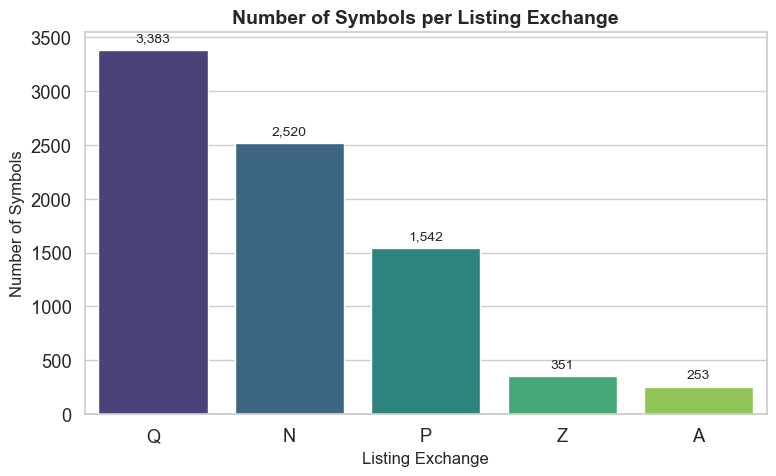

In [7]:
# Ensure plots look clean
sns.set(style="whitegrid", font_scale=1.2)

# Count how many symbols per listing exchange
exchange_counts = meta["listing_exchange"].value_counts().reset_index()
exchange_counts.columns = ["listing_exchange", "count"]

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=exchange_counts,
    x="listing_exchange",
    y="count",
    palette="viridis"
)

# Title and labels
plt.title("Number of Symbols per Listing Exchange", fontsize=14, weight="bold")
plt.xlabel("Listing Exchange", fontsize=12)
plt.ylabel("Number of Symbols", fontsize=12)

# Annotate bar tops
for i, row in exchange_counts.iterrows():
    ax.text(i, row["count"] + 50, f"{row['count']:,}", ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()


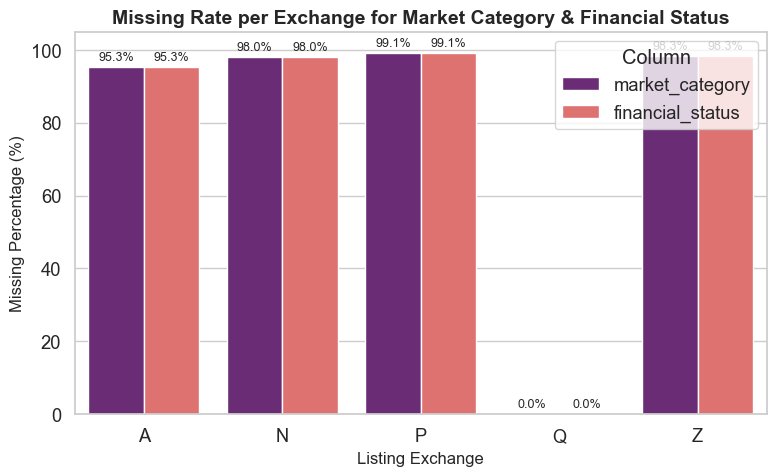

In [8]:
# Compute missing rates per listing_exchange for the 2 columns
cols_to_check = ["market_category", "financial_status"]

missing_rates = (
    meta_enriched.groupby("listing_exchange")[cols_to_check]
    .apply(lambda x: x.isna().mean() * 100)
    .reset_index()
    .melt(id_vars="listing_exchange", var_name="column", value_name="missing_percentage")
)

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(
    data=missing_rates,
    x="listing_exchange",
    y="missing_percentage",
    hue="column",
    palette="magma"
)

plt.title("Missing Rate per Exchange for Market Category & Financial Status", fontsize=14, weight="bold")
plt.xlabel("Listing Exchange", fontsize=12)
plt.ylabel("Missing Percentage (%)", fontsize=12)
plt.legend(title="Column", loc="upper right")
plt.ylim(0, 105)

# Annotate bars
for container in plt.gca().containers:
    plt.bar_label(container, fmt="%.1f%%", label_type="edge", fontsize=9, padding=3)

plt.tight_layout()
plt.show()


With the enrichment step, we managed to fill missing market categories label for the Nasdaq listing exchange

/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_34160/3103935774.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=meta_q, x="market_category", palette="Set2")


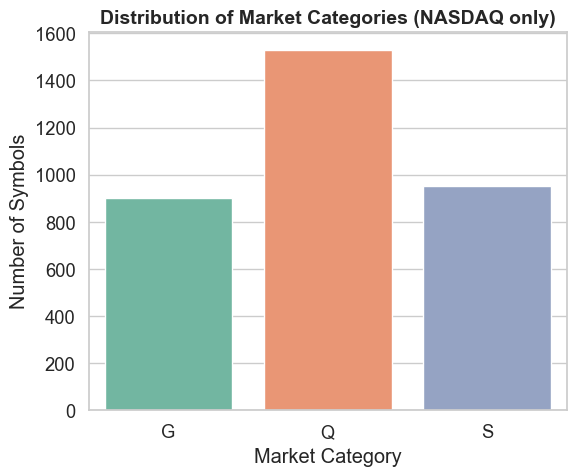

In [9]:
meta_q = meta_enriched[meta_enriched["listing_exchange"] == "Q"]

plt.figure(figsize=(6, 5))
sns.countplot(data=meta_q, x="market_category", palette="Set2")
plt.title("Distribution of Market Categories (NASDAQ only)", fontsize=14, weight="bold")
plt.xlabel("Market Category")
plt.ylabel("Number of Symbols")
plt.tight_layout()
plt.show()


/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_34160/3221036588.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


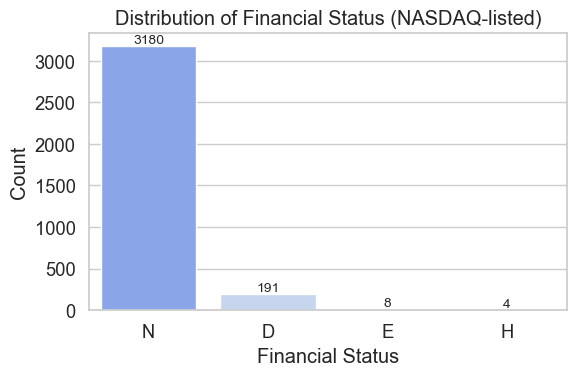

In [10]:
# Drop missing values to avoid NaN bar
data = meta_q.dropna(subset=["financial_status"])

plt.figure(figsize=(6,4))
ax = sns.countplot(
    data=data,
    x="financial_status",
    palette="coolwarm",
)

# add counts on top
for container in ax.containers:
    ax.bar_label(container, fmt="%d", label_type="edge", fontsize=10)

plt.title("Distribution of Financial Status (NASDAQ-listed)")
plt.xlabel("Financial Status")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


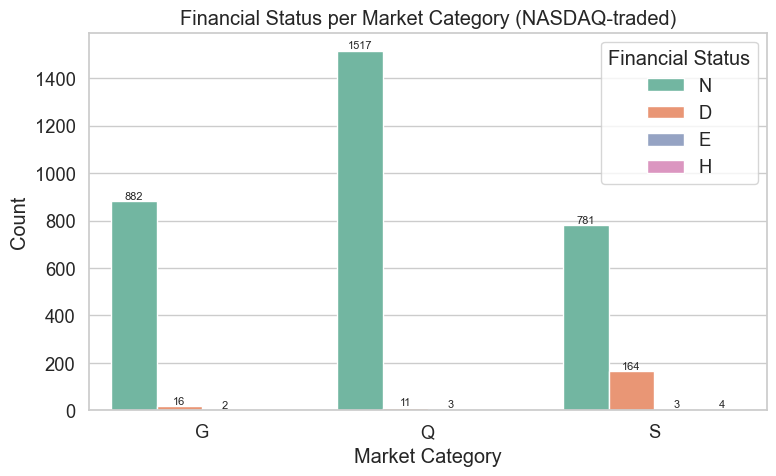

In [11]:
# remove NaN entries in both columns
df = meta_q.dropna(subset=["market_category", "financial_status"])

plt.figure(figsize=(8,5))
ax = sns.countplot(
    data=df,
    x="market_category",
    hue="financial_status",
    palette="Set2"
)

plt.title("Financial Status per Market Category (NASDAQ-traded)")
plt.xlabel("Market Category")
plt.ylabel("Count")

# make legend clear
plt.legend(title="Financial Status")

# add labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", label_type="edge", fontsize=8)

plt.tight_layout()
plt.show()


Financial status has been studied in case we wanted to performn subsequent analysis, but do not seem relevant to study as almost all stocks and ETF have the same status

In [12]:
from src.utils.metadata_enrich import add_sector_column

ORIGINAL_METADATA = "/Users/chedliabdennebi/Desktop/ADA/projet/data/metadata_enriched.csv"
SECTOR_METADATA = "/Users/chedliabdennebi/Desktop/ADA/projet/data/enriched_metadata.csv"
FINAL_METADATA = "/Users/chedliabdennebi/Desktop/ADA/projet/data/final_metadata.csv"

# create final metadata
add_sector_column(ORIGINAL_METADATA, SECTOR_METADATA, FINAL_METADATA)

Saved merged file to: /Users/chedliabdennebi/Desktop/ADA/projet/data/final_metadata.csv


In [17]:
import pandas as pd
from pathlib import Path

# Paths
CLEANED_DIR = Path("data_cleaned")
PROCESSED_DIR = Path("data_processed")
CLEANED_DIR.mkdir(exist_ok=True)
PROCESSED_DIR.mkdir(exist_ok=True)

# IMPORTANT: FINAL_METADATA must be the PATH to your CSV
# If FINAL_METADATA is already a string path, keep it
# If not, set it manually like:
# FINAL_METADATA = "/Users/.../final_metadata.csv"

# Load the final metadata CSV created earlier
final_meta_df = pd.read_csv(FINAL_METADATA)

# -------------------------------
# Export parquet for pipeline
# -------------------------------
final_meta_df.to_parquet(
    PROCESSED_DIR / "metadata_clean.parquet",
    index=False
)

# -------------------------------
# Optional: save CSV copy
# -------------------------------
meta_dir = CLEANED_DIR / "metadata"
meta_dir.mkdir(parents=True, exist_ok=True)

final_meta_df.to_csv(
    meta_dir / "metadata_clean.csv",
    index=False
)

print(f"Columns: {list(final_meta_df.columns)}")


Columns: ['nasdaq_traded', 'symbol', 'security_name', 'listing_exchange', 'market_category', 'etf', 'round_lot_size', 'test_issue', 'financial_status', 'nasdaq_symbol', 'nextshares', 'market_category_label', 'financial_status_label', 'Sector']
